# Task 5  GAN


In [1]:
from pathlib import Path
import random
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms


I change the NUM_EPOCHS to 60 in order get better performance, keeping dataset size to 30k

In [ ]:
SEED = 42
LATENT_DIM = 100
BATCH_SIZE = 256
NUM_EPOCHS = 60 
LEARNING_RATE = 1e-4
BETAS = (0.5, 0.999)
REAL_LABEL = 0.9 
FAKE_LABEL = 0.1
FAST_TRAIN_SAMPLES = 30000 


PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [3]:
def set_seed(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def build_subset_indices(dataset_size, subset_size, seed):
    # random pick of indices
    generator = torch.Generator()
    generator.manual_seed(seed)
    permutation = torch.randperm(dataset_size, generator=generator).tolist()
    return permutation[:subset_size]

In [ ]:
class Generator(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.main = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(True),
            nn.BatchNorm1d(256), 
            nn.Linear(256, 512),
            nn.ReLU(True),
            nn.BatchNorm1d(512),
            nn.Linear(512, 1024),
            nn.ReLU(True),
            nn.BatchNorm1d(1024),
            nn.Linear(1024, 784), 
            nn.Tanh(), 
        )

    def forward(self, z):
        return self.main(z).view(-1, 1, 28, 28)

In [5]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.main = nn.Sequential(
            nn.Linear(784, 512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, 1),
        )

    def forward(self, img):
        img_flat = img.view(img.size(0), -1)
        return self.main(img_flat)

In [6]:


def build_dataloader():
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,)),
    ])
    full_dataset = datasets.MNIST(
        root=str(DATA_DIR),
        train=True,
        download=True,
        transform=transform,
    )

    # only use small part of the data
    subset_indices = build_subset_indices(
        dataset_size=len(full_dataset),
        subset_size=min(FAST_TRAIN_SAMPLES, len(full_dataset)),
        seed=SEED,
    )
    dataset = Subset(full_dataset, subset_indices)
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)


In [ ]:
def train_gan(generator, discriminator, train_loader, device):
    
    # BCEWithLogitsLoss does not change the theoretical loss “sigmoid + BCE”
    # it changes the way its calculated, to avoid numerical problems when the logits are very large or small
    criterion = nn.BCEWithLogitsLoss()   

    optimizer_g = optim.Adam(generator.parameters(), lr=LEARNING_RATE, betas=BETAS)   
    optimizer_d = optim.Adam(discriminator.parameters(), lr=LEARNING_RATE, betas=BETAS)


    history = {  
        "epoch": [],
        "d_loss": [],
        "g_loss": [],
        "d_acc": [],
    }


    for epoch in range(1, NUM_EPOCHS + 1):
        generator.train()  
        discriminator.train()

        total_d_loss = 0.0
        total_g_loss = 0.0   
        total_d_acc = 0.0
        batch_count = 0

        for real_imgs, _ in train_loader:
            real_imgs = real_imgs.to(device)   
            batch_size = real_imgs.size(0)
            
            # soft labels:
            # real images are labeled with REAL_LABEL 0.9 instead of exactly 1
            # fake images are labeled with FAKE_LABEL 0.1 instead of exactly 0
            real_labels = torch.full((batch_size, 1), REAL_LABEL, device=device)  
            fake_labels = torch.full((batch_size, 1), FAKE_LABEL, device=device)

            optimizer_d.zero_grad()     


            real_outputs = discriminator(real_imgs)   # prediction on real images by D
            real_loss = criterion(real_outputs, real_labels)

            #generate a batch of fake images from random noise
            z = torch.randn(batch_size, LATENT_DIM, device=device)   
            fake_imgs = generator(z)
            
            
            # discriminator prediction on fake images
            fake_outputs = discriminator(fake_imgs.detach())  #detach is used so we can use fake images for D, 
                                                            #but do not send gradients back into the generator in this step

            fake_loss = criterion(fake_outputs, fake_labels)

            d_loss = real_loss+fake_loss   # total D loss
            d_loss.backward()
            optimizer_d.step()   

            # Train generator
            
            for p in discriminator.parameters():
                p.requires_grad = False# temporarily freeze discriminator so only generator is updated


            optimizer_g.zero_grad()

            z = torch.randn(batch_size, LATENT_DIM, device=device)#generate a new batch of fake images for the generator step

            fake_imgs = generator(z)   # generate new fake batch
            fake_outputs_for_g = discriminator(fake_imgs)  #pass fake images through the discr.
            
             # the generator wants fake images to be classified as real
            generator_targets = torch.ones((batch_size, 1), device=device)   
            g_loss = criterion(fake_outputs_for_g, generator_targets)

            g_loss.backward()   
            optimizer_g.step()
            for p in discriminator.parameters():
                p.requires_grad = True   # unfreeze Discr. parameters for next iteration

            with torch.no_grad():
                real_correct = (real_outputs > 0).float().mean()   
                fake_correct = (fake_outputs < 0).float().mean()
                d_acc = (real_correct + fake_correct) / 2.0   #final discriminator accuracy = average of the 2

            total_d_loss += d_loss.item()
            total_g_loss += g_loss.item()
            total_d_acc += d_acc.item()
            batch_count += 1   

        avg_d_loss = total_d_loss / batch_count
        avg_g_loss = total_g_loss / batch_count
        avg_d_acc = total_d_acc / batch_count   

        history["epoch"].append(epoch)
        history["d_loss"].append(avg_d_loss)
        history["g_loss"].append(avg_g_loss)
        history["d_acc"].append(avg_d_acc)   

        print(f"Epoch [{epoch}/{NUM_EPOCHS}]  ,  "f"D Loss: {avg_d_loss:.4f}  ,  "f"G Loss: {avg_g_loss:.4f}  ,  "
            f"D Acc: {avg_d_acc:.4f}")   

    return history  

In [8]:

def plot_training_curves(history):
    epochs = history["epoch"]

    plt.figure(figsize=(15, 6))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, history["d_loss"], label="Discriminator Loss")
    plt.plot(epochs, history["g_loss"], label="Generator Loss")
    plt.title("GAN Training Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, history["d_acc"], label="Discriminator Accuracy", color="green")
    plt.axhline(y=0.5, color="red", linestyle="--", label="Random Guess (0.5)")
    plt.title("Discriminator Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.tight_layout()


def sample_noise(num_samples, seed, device):
    torch.manual_seed(seed)
    return torch.randn(num_samples, LATENT_DIM, device=device)




100%|██████████| 9.91M/9.91M [00:00<00:00, 18.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 487kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.49MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.43MB/s]


Epoch [1/60]  ,  D Loss: 0.8529  ,  G Loss: 1.1066  ,  D Acc: 0.9495
Epoch [2/60]  ,  D Loss: 0.7751  ,  G Loss: 1.4944  ,  D Acc: 0.9812
Epoch [3/60]  ,  D Loss: 0.9744  ,  G Loss: 1.3177  ,  D Acc: 0.8554
Epoch [4/60]  ,  D Loss: 0.9301  ,  G Loss: 1.4736  ,  D Acc: 0.9090
Epoch [5/60]  ,  D Loss: 1.0432  ,  G Loss: 1.2552  ,  D Acc: 0.8299
Epoch [6/60]  ,  D Loss: 1.1724  ,  G Loss: 0.9454  ,  D Acc: 0.7507
Epoch [7/60]  ,  D Loss: 1.1899  ,  G Loss: 0.9220  ,  D Acc: 0.7375
Epoch [8/60]  ,  D Loss: 1.1883  ,  G Loss: 0.9368  ,  D Acc: 0.7415
Epoch [9/60]  ,  D Loss: 1.1767  ,  G Loss: 0.9944  ,  D Acc: 0.7534
Epoch [10/60]  ,  D Loss: 1.2126  ,  G Loss: 0.9673  ,  D Acc: 0.7249
Epoch [11/60]  ,  D Loss: 1.2323  ,  G Loss: 0.9296  ,  D Acc: 0.7100
Epoch [12/60]  ,  D Loss: 1.2277  ,  G Loss: 0.9390  ,  D Acc: 0.7149
Epoch [13/60]  ,  D Loss: 1.2661  ,  G Loss: 0.8869  ,  D Acc: 0.6848
Epoch [14/60]  ,  D Loss: 1.2879  ,  G Loss: 0.8358  ,  D Acc: 0.6631
Epoch [15/60]  ,  D Loss: 1.2

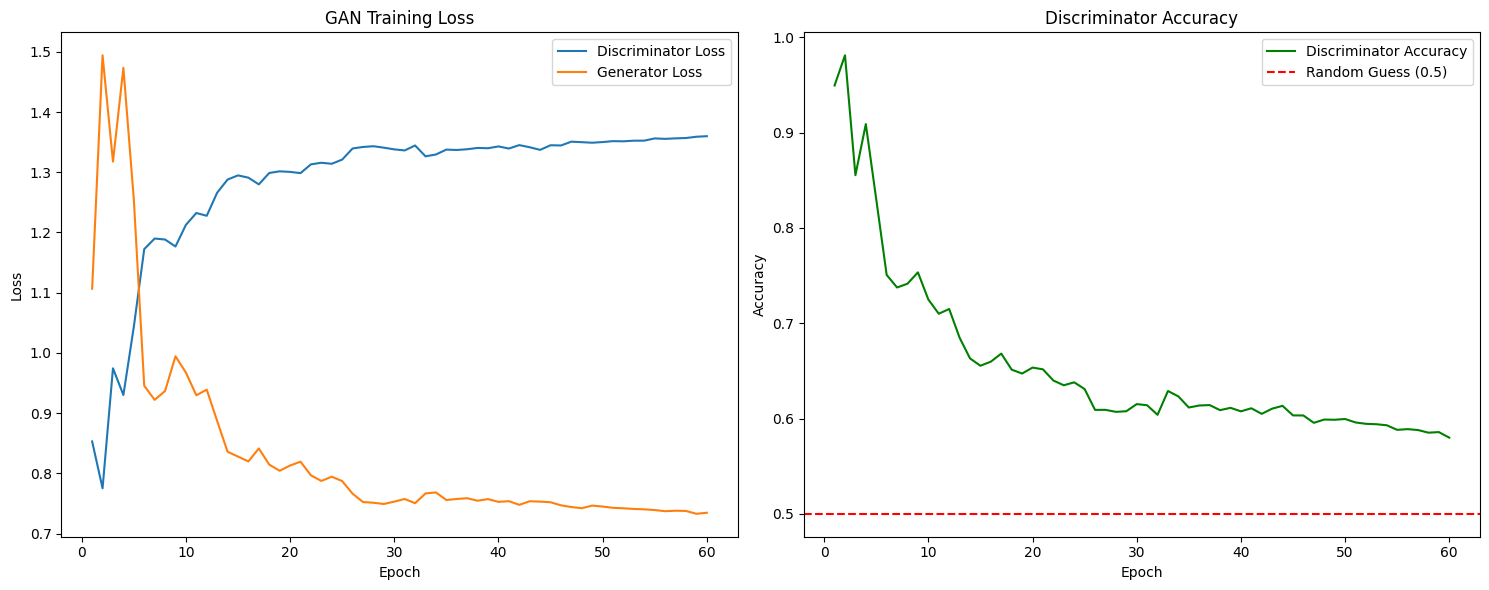

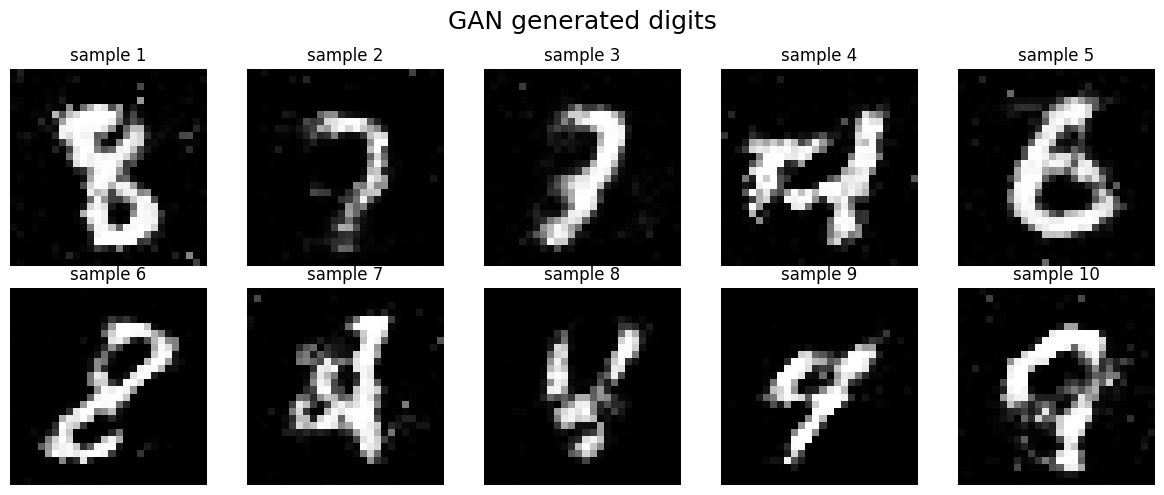

Final D loss: 1.3599
Final G loss: 0.7345
Final D accuracy: 0.5799


In [9]:
# Actual execution of the training
set_seed(SEED)
generator = Generator(LATENT_DIM).to(device)
discriminator = Discriminator().to(device)

train_loader = build_dataloader()



history = train_gan(generator, discriminator, train_loader, device)

plot_training_curves(history)
generator.eval()
with torch.no_grad():
    z = sample_noise(num_samples=10, seed=SEED, device=device)
    generated_samples = (generator(z).cpu() + 1) / 2.0


fig, axes = plt.subplots(2, 5, figsize=(12, 5))



for index, ax in enumerate(axes.flat):
    ax.imshow(generated_samples[index].squeeze(), cmap="gray")
    ax.set_title(f"sample {index + 1}")
    ax.axis("off")

plt.suptitle("GAN generated digits", fontsize=18)
plt.tight_layout()
plt.show()


print(f"Final D loss: {history['d_loss'][-1]:.4f}")
print(f"Final G loss: {history['g_loss'][-1]:.4f}")
print(f"Final D accuracy: {history['d_acc'][-1]:.4f}")

We obtain results that are quite similar to that ones of the previous experiment, but the loss curves appear  more stable and show better convergence. This improvement is due to the longer training, since the number of epochs was increased from 40 to 60. This is consistent with what we  expect when a model has not yet converged in a stable way:namely allowing more training time can help a loss to evolve more smoothly and reach a more stable behaviour 

From the generated images, the model may appear slightly better than in the previous experiment, however, the loss curves and the final values are very simila. This suggests that the  impression from just 10 generated sample can be misleading, because GAN outputs are stochastic and these are not enough to evaluate them reliably

In the next experiment I ll set the number of epochs to 100 because from the plots we can see that the losses and accuracy are not stable yet. so pushing forward the training could be a way to get bettter performance